# Анализ цен предложения квартир в Астане

## 1. Паспорт датасета и вопросы исследования

В этой работе я исследую цены предложения квартир в Астане на основе объявлений Krisha.kz. Данные относятся к марту 2026 года. Цель исследования — сравнить стоимость квартир по районам, количеству комнат и типам домов.

### Источник данных

**Название датасета:** Astana Real Estate Dataset

**Автор:** turarr

**Платформа:** Kaggle

**Источник объявлений:** Krisha.kz

**Ссылка:** https://www.kaggle.com/datasets/turarr/astana-real-estate-dataset

**Период данных:** конец марта 2026 года

**Дата скачивания:** 17 ноября 2026 года

**Название файла:** astana_real_estate_dataset.csv

**Лицензия:** CC0: Public Domain

**Формат:** CSV

### Единица наблюдения

Одна строка датасета — одно объявление о продаже квартиры в Астане, содержащее цену предложения и характеристики объекта недвижимости.

### Словарь столбцов

| Столбец | Описание | Единица измерения |
|---|---|---|
| price | Цена предложения квартиры | тенге |
| rooms | Количество комнат | комнаты |
| area_m2 | Общая площадь квартиры | м² |
| district | Административный район | категория |
| building_type | Тип дома | категория |
| current_floor | Этаж квартиры | этаж |
| Год постройки | Год постройки дома | год |
| url | Ссылка на объявление | ссылка |

### Вопросы исследования

1. В каком районе Астаны самая высокая медианная цена предложения за квадратный метр?
2. Как различается медианная цена квадратного метра в зависимости от количества комнат?
3. Как различается медианная цена квадратного метра в кирпичных, монолитных и панельных домах?

### Практическая польза исследования

Результаты исследования могут быть полезны покупателям квартир, риелторам, инвесторам и аналитикам рынка недвижимости для сравнения цен предложения и характеристик объектов.

Анализ основан на объявлениях марта 2026 года и не отражает фактические цены заключённых сделок.

## 2. Загрузка и первое знакомство с данными

In [1]:
import pandas as pd

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

csv_path = data_dir / "astana_real_estate_dataset.csv"

source_url = (
    "https://raw.githubusercontent.com/"
    "Turarr/Krisha.kz-Astana-Real-Estate-Dataset/"
    "main/astana_real_estate_dataset.csv"
)

if not csv_path.exists():
    urlretrieve(source_url, csv_path)

raw_df = pd.read_csv(csv_path)
df = raw_df.copy()

print("Размер исходного датасета:", raw_df.shape)

Размер исходного датасета: (5003, 23)


In [3]:
df.head(5)

,url,title,price,security,ceiling_height,Год постройки,district,residential_complex,furnished,parking,...,rooms,current_floor,total_floors,area_m2,address,district_lat,district_lon,apartment_lat,apartment_lon,coord_level
0,https://krisha.kz/a/show/683656844,"3-комнатная квартира · 120 м², Сыганак — Кабан...",55000000,"домофон, видеонаблюдение",2.902672,2006,"Есильский район, Астана, Казахстан",7 Бочек,полностью,Во дворе/не указано,...,3.0,6.0,11.0,120.00,Сыганак — Кабанбай батыра,51.120,71.430,51.122041,71.413101,Address
1,https://krisha.kz/a/show/1010380882,"2-комнатная квартира · 64.5 м² · 9/9 этаж, Тол...",45500000,"домофон, видеонаблюдение",3.000000,2022,"Нуринский район, Астана, Казахстан",Dastur,полностью,Во дворе/не указано,...,2.0,9.0,9.0,64.50,Толе би 25,51.100,71.380,51.099779,71.389694,Complex
2,https://krisha.kz/a/show/1010251370,"2-комнатная квартира · 64.37 м² · 10/12 этаж, ...",32800000,"домофон, кодовый замок, видеодомофон",3.000000,2026,"Сарыаркинский район, Астана, Казахстан",Shalqar,без мебели,паркинг,...,2.0,10.0,12.0,64.37,Чингиз Айтматов 77/11 — Мечеть Ырыскелді Кажы,51.170,71.410,51.170000,71.410000,District
3,https://krisha.kz/a/show/1010195327,"3-комнатная квартира · 115 м², Ивана Панфилова 85",75000000,"домофон, видеонаблюдение",3.200000,2026,"Сарыаркинский район, Астана, Казахстан",TANSU,без мебели,паркинг,...,3.0,6.0,11.0,115.00,Ивана Панфилова 85,51.117,71.565,51.105860,71.500377,Complex
4,https://krisha.kz/a/show/1009176178,"2-комнатная квартира · 52 м² · 8/12 этаж, Кубр...",25000000,"домофон, видеонаблюдение",2.700000,2009,"Сарыаркинский район, Астана, Казахстан",Сайран,полностью,Во дворе/не указано,...,2.0,8.0,12.0,52.00,Кубрина 20/1,51.170,71.410,51.197097,71.475239,Complex


In [4]:
df.head(1)

,url,title,price,security,ceiling_height,Год постройки,district,residential_complex,furnished,parking,...,rooms,current_floor,total_floors,area_m2,address,district_lat,district_lon,apartment_lat,apartment_lon,coord_level
0,https://krisha.kz/a/show/683656844,"3-комнатная квартира · 120 м², Сыганак — Кабан...",55000000,"домофон, видеонаблюдение",2.902672,2006,"Есильский район, Астана, Казахстан",7 Бочек,полностью,Во дворе/не указано,...,3.0,6.0,11.0,120.0,Сыганак — Кабанбай батыра,51.12,71.43,51.122041,71.413101,Address


In [5]:
df.head(10)

,url,title,price,security,ceiling_height,Год постройки,district,residential_complex,furnished,parking,...,rooms,current_floor,total_floors,area_m2,address,district_lat,district_lon,apartment_lat,apartment_lon,coord_level
0,https://krisha.kz/a/show/683656844,"3-комнатная квартира · 120 м², Сыганак — Кабан...",55000000,"домофон, видеонаблюдение",2.902672,2006,"Есильский район, Астана, Казахстан",7 Бочек,полностью,Во дворе/не указано,...,3.0,6.0,11.0,120.00,Сыганак — Кабанбай батыра,51.120,71.430,51.122041,71.413101,Address
1,https://krisha.kz/a/show/1010380882,"2-комнатная квартира · 64.5 м² · 9/9 этаж, Тол...",45500000,"домофон, видеонаблюдение",3.000000,2022,"Нуринский район, Астана, Казахстан",Dastur,полностью,Во дворе/не указано,...,2.0,9.0,9.0,64.50,Толе би 25,51.100,71.380,51.099779,71.389694,Complex
2,https://krisha.kz/a/show/1010251370,"2-комнатная квартира · 64.37 м² · 10/12 этаж, ...",32800000,"домофон, кодовый замок, видеодомофон",3.000000,2026,"Сарыаркинский район, Астана, Казахстан",Shalqar,без мебели,паркинг,...,2.0,10.0,12.0,64.37,Чингиз Айтматов 77/11 — Мечеть Ырыскелді Кажы,51.170,71.410,51.170000,71.410000,District
3,https://krisha.kz/a/show/1010195327,"3-комнатная квартира · 115 м², Ивана Панфилова 85",75000000,"домофон, видеонаблюдение",3.200000,2026,"Сарыаркинский район, Астана, Казахстан",TANSU,без мебели,паркинг,...,3.0,6.0,11.0,115.00,Ивана Панфилова 85,51.117,71.565,51.105860,71.500377,Complex
4,https://krisha.kz/a/show/1009176178,"2-комнатная квартира · 52 м² · 8/12 этаж, Кубр...",25000000,"домофон, видеонаблюдение",2.700000,2009,"Сарыаркинский район, Астана, Казахстан",Сайран,полностью,Во дворе/не указано,...,2.0,8.0,12.0,52.00,Кубрина 20/1,51.170,71.410,51.197097,71.475239,Complex
5,https://krisha.kz/a/show/1008941883,"1-комнатная квартира · 38 м² · 7/10 этаж, Карт...",13800000,"домофон, видеонаблюдение",2.850000,2026,"Сарыаркинский район, Астана, Казахстан",ЛЕЯ-Уют,без мебели,паркинг,...,1.0,7.0,10.0,38.00,Карталинская 29/1,51.170,71.410,51.197321,71.386875,Address
6,https://krisha.kz/a/show/1007604244,"3-комнатная квартира · 96.11 м² · 12/12 этаж, ...",40366200,"домофон, видеонаблюдение",3.000000,2026,"Сарыаркинский район, Астана, Казахстан",Панельный дом/Не указан,без мебели,Во дворе/не указано,...,3.0,12.0,12.0,96.11,Калдаяков,51.117,71.565,51.116947,71.469397,Address
7,https://krisha.kz/a/show/1006792530,"1-комнатная квартира · 34 м² · 9/10 этаж, Муст...",19500000,"домофон, видеонаблюдение",2.700000,2008,"Алматинский район, Астана, Казахстан",Достар-2,полностью,Во дворе/не указано,...,1.0,9.0,10.0,34.00,Мустафина 21/5,51.150,71.500,51.158299,71.506524,Complex
8,https://krisha.kz/a/show/1006435460,"2-комнатная квартира · 48.8 м² · 9 этаж, Улы Д...",34999999,"домофон, видеонаблюдение",2.700000,2019,"Есильский район, Астана, Казахстан",Alan,полностью,Во дворе/не указано,...,2.0,6.0,11.0,48.80,Улы Дала 61 — Улы Дала Жошы Хан,51.120,71.430,51.094535,71.439394,Complex
9,https://krisha.kz/a/show/1004570435,"2-комнатная квартира · 60.2 м² · 1/12 этаж, Ул...",41000000,"домофон, видеонаблюдение, видеодомофон",3.000000,2024,"Есильский район, Астана, Казахстан",Vienna,полностью,паркинг,...,2.0,1.0,12.0,60.20,Ул.Жошы хан 13 — Бокейхана-Бухар Жырау,51.120,71.430,51.084111,71.429427,Complex


In [6]:
df.tail(5)

,url,title,price,security,ceiling_height,Год постройки,district,residential_complex,furnished,parking,...,rooms,current_floor,total_floors,area_m2,address,district_lat,district_lon,apartment_lat,apartment_lon,coord_level
4998,https://krisha.kz/a/show/1010824429,"3-комнатная квартира · 87 м² · 4/9 этаж, Е-36,...",48000000,"домофон, видеонаблюдение",3.0,2025,"Нуринский район, Астана, Казахстан",Respublika,без мебели,паркинг,...,3.0,4.0,9.0,87.0,"Е-36, 6 6 — Е-36,6",51.10,71.38,51.123396,71.383589,Complex
4999,https://krisha.kz/a/show/1010813344,"1-комнатная квартира · 44.5 м² · 10/12 этаж, А...",28000000,"домофон, видеонаблюдение",2.7,2014,"Есильский район, Астана, Казахстан",Грация,полностью,паркинг,...,1.0,10.0,12.0,44.5,"Акмешит 7, 7а, 7/1, 7/3",51.12,71.43,51.172880,71.413326,Complex
5000,https://krisha.kz/a/show/1008611465,"3-комнатная квартира · 105.1 м² · 4/8 этаж, Ка...",56000000,"домофон, видеонаблюдение",3.0,2022,"Алматинский район, Астана, Казахстан",Мынжылдык,без мебели,паркинг,...,3.0,4.0,8.0,105.1,Калдаякова — Калдаякова и Ахмедьярова,51.15,71.50,51.112353,71.498305,Complex
5001,https://krisha.kz/a/show/1010095677,"4-комнатная квартира · 160 м² · 12/21 этаж, Ка...",187199999,"решетки на окнах, охрана, домофон, видеонаблюд...",2.9,2022,"Алматинский район, Астана, Казахстан",Highvill Ishim C,полностью,паркинг,...,4.0,12.0,21.0,160.0,Калдаякова,51.15,71.50,51.118829,71.459120,Complex
5002,https://krisha.kz/a/show/1010702963,"3-комнатная квартира · 93 м² · 4/9 этаж, Чинги...",42990000,"домофон, видеонаблюдение",2.7,2017,"Нуринский район, Астана, Казахстан",Меркурий,без мебели,паркинг,...,3.0,4.0,9.0,93.0,Чингиз Айтматов 29а,51.10,71.38,51.130082,71.360099,Complex


In [7]:
df.sample(5, random_state=42)

,url,title,price,security,ceiling_height,Год постройки,district,residential_complex,furnished,parking,...,rooms,current_floor,total_floors,area_m2,address,district_lat,district_lon,apartment_lat,apartment_lon,coord_level
414,https://krisha.kz/a/show/1002708578,"2-комнатная квартира · 69.44 м², Шафика Чокина 4",51859813,"домофон, видеонаблюдение",3.00,2026,"Нуринский район, Астана, Казахстан",TULGA,без мебели,Во дворе/не указано,...,2.0,6.0,11.0,69.44,Шафика Чокина 4,51.100,71.380,51.100000,71.380000,District
1815,https://krisha.kz/a/show/1009966514,"1-комнатная квартира · 42 м² · 7/17 этаж, Буха...",30500000,"домофон, видеонаблюдение",3.00,2026,"Астана, Казахстан",Sandi Qala,без мебели,паркинг,...,1.0,7.0,17.0,42.00,Бухар Жырау 12/3,51.133,71.433,51.101777,71.440282,Complex
642,https://krisha.kz/a/show/1010310685,"2-комнатная квартира · 63.28 м² · 1/4 этаж, E6...",24000000,"домофон, видеонаблюдение",2.70,2026,"Есильский район, Астана, Казахстан",Панельный дом/Не указан,без мебели,Во дворе/не указано,...,2.0,1.0,4.0,63.28,E669 225 — Улы Дала,51.120,71.430,51.120000,71.430000,District
1056,https://krisha.kz/a/show/1002501203,"4-комнатная квартира · 125.47 м², Р. Кошкарбае...",84064900,"домофон, видеонаблюдение",3.00,2027,"Сарыаркинский район, Астана, Казахстан",Saryn,без мебели,Во дворе/не указано,...,4.0,6.0,11.0,125.47,Р. Кошкарбаева — К. Куанышбаева,51.117,71.565,51.134068,71.519752,Complex
4507,https://krisha.kz/a/show/1010814271,"2-комнатная квартира · 59.8 м² · 9/14 этаж, Ул...",36500000,"домофон, видеонаблюдение",2.65,2026,"Нуринский район, Астана, Казахстан",UIA.DARYN,без мебели,паркинг,...,2.0,9.0,14.0,59.80,Улы Дала,51.100,71.380,51.105442,71.351792,Complex


In [8]:
df.columns

Index(['url', 'title', 'price', 'security', 'ceiling_height', 'Год постройки',
       'district', 'residential_complex', 'furnished', 'parking',
       'bathroom_type', 'apartment_condition', 'building_type', 'rooms',
       'current_floor', 'total_floors', 'area_m2', 'address', 'district_lat',
       'district_lon', 'apartment_lat', 'apartment_lon', 'coord_level'],
      dtype='object')

In [9]:
df.columns.tolist()

['url',
 'title',
 'price',
 'security',
 'ceiling_height',
 'Год постройки',
 'district',
 'residential_complex',
 'furnished',
 'parking',
 'bathroom_type',
 'apartment_condition',
 'building_type',
 'rooms',
 'current_floor',
 'total_floors',
 'area_m2',
 'address',
 'district_lat',
 'district_lon',
 'apartment_lat',
 'apartment_lon',
 'coord_level']

In [10]:
df.dtypes

,0
url,object
title,object
price,int64
security,object
ceiling_height,float64
Год постройки,int64
district,object
residential_complex,object
furnished,object
parking,object


In [11]:
df.info()

print("\nКоличество строк и столбцов:", df.shape)

print("\nПропущенные значения по столбцам:")
print(df.isna().sum().sort_values(ascending=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5003 entries, 0 to 5002
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   url                  5003 non-null   object 
 1   title                5003 non-null   object 
 2   price                5003 non-null   int64  
 3   security             5003 non-null   object 
 4   ceiling_height       5003 non-null   float64
 5   Год постройки        5003 non-null   int64  
 6   district             5003 non-null   object 
 7   residential_complex  5003 non-null   object 
 8   furnished            5003 non-null   object 
 9   parking              5003 non-null   object 
 10  bathroom_type        5003 non-null   object 
 11  apartment_condition  5003 non-null   object 
 12  building_type        5003 non-null   object 
 13  rooms                5003 non-null   float64
 14  current_floor        5003 non-null   float64
 15  total_floors         5003 non-null   f

### Выводы по первоначальному знакомству с данными

Исходный датасет содержит 5 003 строки и 23 столбца. Каждая строка соответствует одному объявлению о продаже квартиры.

В таблице присутствуют числовые данные (int64, float64) и текстовые категориальные данные (object).

Команда head() показывает первые строки, tail() — последние, а sample() позволяет выбрать случайные записи.

Первые строки не заменяют случайную выборку, поскольку порядок записей в исходном файле может влиять на то, какие квартиры мы увидим.

Параметр random_state=42 позволяет воспроизводить одинаковую случайную выборку при неизменных данных.

Все 23 столбца содержат по 5 003 непустых значения. Проверка isna() не выявила пропусков. Однако датасет предварительно обработан автором, поэтому необходимо дополнительно проверить достоверность значений, диапазоны цен и площадей, а также наличие дубликатов.

## 3. Выбор строк, столбцов и сортировка

In [12]:
price_series = df["price"]
price_dataframe = df[["price"]]

print(type(price_series))
print(type(price_dataframe))

<class 'pandas.core.series.Series'>
<class 'pandas.core.frame.DataFrame'>


In [13]:
print("Первые 10 строк и первые 3 столбца:")
display(df.iloc[:10, :3])

print("Каждая пятая строка, начиная с первой:")
every_fifth = df.iloc[::5, :3]

print("Всего выбранных строк:", len(every_fifth))
display(every_fifth.head(10))

Первые 10 строк и первые 3 столбца:


,url,title,price
0,https://krisha.kz/a/show/683656844,"3-комнатная квартира · 120 м², Сыганак — Кабан...",55000000
1,https://krisha.kz/a/show/1010380882,"2-комнатная квартира · 64.5 м² · 9/9 этаж, Тол...",45500000
2,https://krisha.kz/a/show/1010251370,"2-комнатная квартира · 64.37 м² · 10/12 этаж, ...",32800000
3,https://krisha.kz/a/show/1010195327,"3-комнатная квартира · 115 м², Ивана Панфилова 85",75000000
4,https://krisha.kz/a/show/1009176178,"2-комнатная квартира · 52 м² · 8/12 этаж, Кубр...",25000000
5,https://krisha.kz/a/show/1008941883,"1-комнатная квартира · 38 м² · 7/10 этаж, Карт...",13800000
6,https://krisha.kz/a/show/1007604244,"3-комнатная квартира · 96.11 м² · 12/12 этаж, ...",40366200
7,https://krisha.kz/a/show/1006792530,"1-комнатная квартира · 34 м² · 9/10 этаж, Муст...",19500000
8,https://krisha.kz/a/show/1006435460,"2-комнатная квартира · 48.8 м² · 9 этаж, Улы Д...",34999999
9,https://krisha.kz/a/show/1004570435,"2-комнатная квартира · 60.2 м² · 1/12 этаж, Ул...",41000000


Каждая пятая строка, начиная с первой:
Всего выбранных строк: 1001


,url,title,price
0,https://krisha.kz/a/show/683656844,"3-комнатная квартира · 120 м², Сыганак — Кабан...",55000000
5,https://krisha.kz/a/show/1008941883,"1-комнатная квартира · 38 м² · 7/10 этаж, Карт...",13800000
10,https://krisha.kz/a/show/683962805,"1-комнатная квартира · 38.8 м², Е-36 5",25996000
15,https://krisha.kz/a/show/1006521696,"1-комнатная квартира · 40 м² · 2/9 этаж, Жошы ...",31800000
20,https://krisha.kz/a/show/1010181005,"4-комнатная квартира · 113.61 м², Кенесары 54",64752000
25,https://krisha.kz/a/show/1010411727,"2-комнатная квартира · 52.2 м², Сыганак 26/2",36016000
30,https://krisha.kz/a/show/1010575656,"4-комнатная квартира · 148 м² · 23/26 этаж, Ко...",109000000
35,https://krisha.kz/a/show/1009037438,"2-комнатная квартира · 71 м² · 7/9 этаж, Бокей...",39000000
40,https://krisha.kz/a/show/1009873215,"2-комнатная квартира · 37 м² · 9/10 этаж, Култ...",29700000
45,https://krisha.kz/a/show/1010618378,"3-комнатная квартира · 93 м² · 4/9 этаж, Чинги...",42990000


In [14]:
apartments_2rooms = df.loc[
    (df["rooms"] == 2) & (df["area_m2"] >= 50),
    ["price", "rooms", "area_m2", "district"]
]

print("Количество подходящих квартир:", len(apartments_2rooms))
display(apartments_2rooms.head(10))

Количество подходящих квартир: 1379


,price,rooms,area_m2,district
1,45500000,2.0,64.50,"Нуринский район, Астана, Казахстан"
2,32800000,2.0,64.37,"Сарыаркинский район, Астана, Казахстан"
4,25000000,2.0,52.00,"Сарыаркинский район, Астана, Казахстан"
9,41000000,2.0,60.20,"Есильский район, Астана, Казахстан"
16,29800000,2.0,62.80,"Алматинский район, Астана, Казахстан"
18,36016000,2.0,52.20,"Нуринский район, Астана, Казахстан"
23,29800000,2.0,62.80,"Алматинский район, Астана, Казахстан"
25,36016000,2.0,52.20,"Нуринский район, Астана, Казахстан"
33,45800000,2.0,65.00,"Есильский район, Астана, Казахстан"
34,30300000,2.0,65.00,"Сарыаркинский район, Астана, Казахстан"


In [15]:
top10 = (
    df.dropna(subset=["price"])
      .sort_values("price", ascending=False)
      .head(10)
)

display(top10[["price", "rooms", "area_m2", "district"]])

,price,rooms,area_m2,district
1424,33900000000,2.0,62.0,"Астана, Казахстан"
2973,640000000,6.0,236.0,"Астана, Казахстан"
4819,380000000,4.0,232.0,"Алматинский район, Астана, Казахстан"
3867,375000000,7.0,355.0,"Алматинский район, Астана, Казахстан"
3626,350000000,8.0,430.0,"Сарыаркинский район, Астана, Казахстан"
3650,345000000,5.0,252.0,"Сарыаркинский район, Астана, Казахстан"
2970,330000000,4.0,194.0,"Астана, Казахстан"
560,320000000,6.0,420.0,"Есильский район, Астана, Казахстан"
567,320000000,6.0,420.0,"Есильский район, Астана, Казахстан"
1343,300000000,4.0,149.0,"Есильский район, Астана, Казахстан"


In [16]:
sorted_df = df.sort_values(
    ["district", "price"],
    ascending=[True, False]
)

display(sorted_df[["district", "price", "rooms", "area_m2"]].head(10))

,district,price,rooms,area_m2
4819,"Алматинский район, Астана, Казахстан",380000000,4.0,232.00
3867,"Алматинский район, Астана, Казахстан",375000000,7.0,355.00
3895,"Алматинский район, Астана, Казахстан",219999999,4.0,150.00
2542,"Алматинский район, Астана, Казахстан",194701000,4.0,149.77
2543,"Алматинский район, Астана, Казахстан",194701000,4.0,149.77
3575,"Алматинский район, Астана, Казахстан",191615000,5.0,201.70
5001,"Алматинский район, Астана, Казахстан",187199999,4.0,160.00
3420,"Алматинский район, Астана, Казахстан",185000000,5.0,152.00
4652,"Алматинский район, Астана, Казахстан",179000000,4.0,152.00
2110,"Алматинский район, Астана, Казахстан",165000000,5.0,173.00


### Выводы по выбору и сортировке данных

Один столбец можно получить как Series или DataFrame. Метод iloc выбирает строки и столбцы по их порядковым позициям, а loc позволяет выбирать данные по меткам и логическим условиям.

Срез iloc[::5, :3] выбирает каждую пятую строку, начиная с первой, и первые три столбца.

С помощью фильтра были отобраны двухкомнатные квартиры площадью от 50 м².

Метод sort_values() позволяет сортировать данные по одному или нескольким столбцам с разными направлениями сортировки.

Команда head(10).dropna() может вернуть меньше десяти строк, если среди первых десяти имеются пропуски. Поэтому при построении топ-10 мы сначала исключаем пропуски нужного показателя, затем сортируем данные и выбираем десять строк.

## 4. Качество данных и обоснованная очистка

In [17]:
missing_report = pd.DataFrame({
    "Пропусков": df.isna().sum(),
    "Доля, %": (df.isna().mean() * 100).round(2)
})

display(missing_report)

,Пропусков,"Доля, %"
url,0,0.0
title,0,0.0
price,0,0.0
security,0,0.0
ceiling_height,0,0.0
Год постройки,0,0.0
district,0,0.0
residential_complex,0,0.0
furnished,0,0.0
parking,0,0.0


In [18]:
print("Всего строк:", len(df))

print("Полные дубликаты:", df.duplicated().sum())

print("Повторяющиеся ссылки:", df["url"].duplicated().sum())

print("Цена <= 0:", (df["price"] <= 0).sum())

print("Площадь <= 0:", (df["area_m2"] <= 0).sum())

print("Минимальные значения:")
print(df[["price", "area_m2"]].min())

print("Максимальные значения:")
print(df[["price", "area_m2"]].max())

Всего строк: 5003
Полные дубликаты: 829
Повторяющиеся ссылки: 829
Цена <= 0: 0
Площадь <= 0: 0
Минимальные значения:
price      3500000.0
area_m2         10.0
dtype: float64
Максимальные значения:
price      3.390000e+10
area_m2    7.850000e+02
dtype: float64


In [19]:
expensive = df.nlargest(10, "price")

display(
    expensive[
        ["price", "rooms", "area_m2", "district", "url"]
    ]
)

,price,rooms,area_m2,district,url
1424,33900000000,2.0,62.0,"Астана, Казахстан",https://krisha.kz/a/show/1010843497
2973,640000000,6.0,236.0,"Астана, Казахстан",https://krisha.kz/a/show/1009102934
4819,380000000,4.0,232.0,"Алматинский район, Астана, Казахстан",https://krisha.kz/a/show/1010479033
3867,375000000,7.0,355.0,"Алматинский район, Астана, Казахстан",https://krisha.kz/a/show/693584641
3626,350000000,8.0,430.0,"Сарыаркинский район, Астана, Казахстан",https://krisha.kz/a/show/1009880111
3650,345000000,5.0,252.0,"Сарыаркинский район, Астана, Казахстан",https://krisha.kz/a/show/1007039330
2970,330000000,4.0,194.0,"Астана, Казахстан",https://krisha.kz/a/show/1009206100
560,320000000,6.0,420.0,"Есильский район, Астана, Казахстан",https://krisha.kz/a/show/696863501
567,320000000,6.0,420.0,"Есильский район, Астана, Казахстан",https://krisha.kz/a/show/696863501
1342,300000000,4.0,149.0,"Есильский район, Астана, Казахстан",https://krisha.kz/a/show/1010654546


In [20]:
print("До очистки:", len(df))

df = df.drop_duplicates().copy()

print("После очистки:", len(df))
print("Повторяющиеся URL:", df["url"].duplicated().sum())

До очистки: 5003
После очистки: 4174
Повторяющиеся URL: 0


In [21]:
df["price_per_m2"] = df["price"] / df["area_m2"]

suspicious = df.loc[
    (df["price"] > 1_000_000_000) |
    (df["price_per_m2"] > 10_000_000),
    ["price", "area_m2", "price_per_m2", "url"]
]

display(suspicious)

,price,area_m2,price_per_m2,url
1424,33900000000,62.0,5.467742e+08,https://krisha.kz/a/show/1010843497


In [22]:
analysis_df = df.loc[
    ~df.index.isin(suspicious.index)
].copy()

print("После удаления дублей:", len(df))
print("Для анализа цен:", len(analysis_df))
print("Исключено подозрительных записей:", len(df) - len(analysis_df))

После удаления дублей: 4174
Для анализа цен: 4173
Исключено подозрительных записей: 1


In [23]:
print("Средняя цена с выбросом:")
print(df["price"].mean().round(0))

print("Средняя цена без выброса:")
print(analysis_df["price"].mean().round(0))

print("Медиана с выбросом:")
print(df["price"].median())

print("Медиана без выброса:")
print(analysis_df["price"].median())

Средняя цена с выбросом:
55328808.0
Средняя цена без выброса:
47218415.0
Медиана с выбросом:
37500000.0
Медиана без выброса:
37500000.0


### Результаты проверки качества данных

В исходном датасете обнаружено 829 полных дубликатов. Для предотвращения повторного учёта одних и тех же объявлений они были удалены.

Пропусков NaN и неположительных значений цены и площади не обнаружено.

При проверке максимальных цен обнаружено подозрительно дорогое объявление о двухкомнатной квартире площадью 62 м² за 33,9 млрд тенге. Это значение требует отдельной проверки перед включением в статистику.

### Итоги очистки данных

Из 5 003 исходных записей удалено 829 полных дубликатов. После удаления повторов осталось 4 174 объявления, повторяющихся URL не обнаружено.

Пропуски NaN, нулевые и отрицательные цены и площади отсутствуют. Однако подготовленные автором значения могут содержать заполненные по умолчанию категории.

Обнаружено одно подозрительное объявление: двухкомнатная квартира площадью 62 м² с ценой предложения 33,9 млрд тенге.

Для основного анализа цен эта запись исключена по предварительно выбранным порогам: цена более 1 млрд тенге или стоимость квадратного метра более 10 млн тенге. Само по себе превышение порога не доказывает ошибку объявления.

Оригинальные данные сохранены в raw_df, таблица без полных повторов — в df, а таблица для основного анализа — в analysis_df.

После удаления 829 полных дубликатов и исключения одного подозрительного объявления для основного анализа осталось 4 173 записи.

## 5. Описательная статистика

В этом разделе исследуются цены предложения квартир и их общая площадь. Для анализа используются данные после очистки.

In [24]:
analysis_df[["price", "area_m2"]].describe().round(2)

,price,area_m2
count,4.173000e+03,4173.00
mean,4.721841e+07,70.58
std,3.484844e+07,38.27
min,3.500000e+06,10.00
25%,2.747430e+07,43.00
50%,3.750000e+07,62.61
75%,5.500000e+07,86.00
max,6.400000e+08,785.00


In [25]:
analysis_df[["price", "area_m2"]].quantile(
    [0.25, 0.50, 0.75, 0.90]
).round(2)

,price,area_m2
0.25,27474300.0,43.00
0.50,37500000.0,62.61
0.75,55000000.0,86.00
0.90,80463432.0,114.27


In [26]:
print("Количество объявлений по районам:")
display(
    analysis_df["district"].value_counts(dropna=False)
)

print("Доля объявлений по районам, %:")
display(
    (
        analysis_df["district"]
        .value_counts(normalize=True, dropna=False) * 100
    ).round(2)
)

Количество объявлений по районам:


,count
district,
"Нуринский район, Астана, Казахстан",1224
"Есильский район, Астана, Казахстан",1115
"Сарыаркинский район, Астана, Казахстан",844
"Алматинский район, Астана, Казахстан",664
"Байконурский район, Астана, Казахстан",179
"Астана, Казахстан",147


Доля объявлений по районам, %:


,proportion
district,
"Нуринский район, Астана, Казахстан",29.33
"Есильский район, Астана, Казахстан",26.72
"Сарыаркинский район, Астана, Казахстан",20.23
"Алматинский район, Астана, Казахстан",15.91
"Байконурский район, Астана, Казахстан",4.29
"Астана, Казахстан",3.52


### Выводы по описательной статистике

После очистки проанализировано 4 173 объявления о продаже квартир.

Средняя цена предложения составляет 47,22 млн тенге, медианная — 37,5 млн тенге. Средняя цена выше медианной, поскольку дорогие квартиры увеличивают среднее значение.

90-й процентиль цены составляет 80,46 млн тенге. Это означает, что около 90% объявлений имеют цену не выше этого уровня.

Средняя площадь квартир составляет 70,58 м², медианная — 62,61 м².

Больше всего объявлений приходится на Нуринский район — 1 224 записи, или 29,33%. Проценты рассчитаны от общего количества 4 173 объявлений.

У 147 объявлений район не уточнён. Это ограничивает точность дальнейшего сравнения районов.

## 6. Фильтры и сравнение двух выборок

In [27]:
filtered = analysis_df.loc[
    (analysis_df["rooms"] == 2) &
    (analysis_df["area_m2"] >= 50),
    ["district", "rooms", "area_m2", "price", "price_per_m2"]
]

print("Количество квартир:", len(filtered))
display(filtered.head(10))

Количество квартир: 1126


,district,rooms,area_m2,price,price_per_m2
1,"Нуринский район, Астана, Казахстан",2.0,64.50,45500000,705426.356589
2,"Сарыаркинский район, Астана, Казахстан",2.0,64.37,32800000,509554.140127
4,"Сарыаркинский район, Астана, Казахстан",2.0,52.00,25000000,480769.230769
9,"Есильский район, Астана, Казахстан",2.0,60.20,41000000,681063.122924
16,"Алматинский район, Астана, Казахстан",2.0,62.80,29800000,474522.292994
18,"Нуринский район, Астана, Казахстан",2.0,52.20,36016000,689961.685824
33,"Есильский район, Астана, Казахстан",2.0,65.00,45800000,704615.384615
34,"Сарыаркинский район, Астана, Казахстан",2.0,65.00,30300000,466153.846154
35,"Есильский район, Астана, Казахстан",2.0,71.00,39000000,549295.774648
39,"Сарыаркинский район, Астана, Казахстан",2.0,54.00,32000000,592592.592593


In [28]:
selected_districts = [
    "Нуринский район, Астана, Казахстан",
    "Есильский район, Астана, Казахстан"
]

two_districts = analysis_df.loc[
    analysis_df["district"].isin(selected_districts)
]

print("Количество квартир:", len(two_districts))

display(
    two_districts[
        ["district", "rooms", "area_m2", "price"]
    ].head(10)
)

Количество квартир: 2339


,district,rooms,area_m2,price
0,"Есильский район, Астана, Казахстан",3.0,120.00,55000000
1,"Нуринский район, Астана, Казахстан",2.0,64.50,45500000
8,"Есильский район, Астана, Казахстан",2.0,48.80,34999999
9,"Есильский район, Астана, Казахстан",2.0,60.20,41000000
10,"Нуринский район, Астана, Казахстан",1.0,38.80,25996000
15,"Есильский район, Астана, Казахстан",1.0,40.00,31800000
18,"Нуринский район, Астана, Казахстан",2.0,52.20,36016000
19,"Нуринский район, Астана, Казахстан",3.0,68.55,43255050
31,"Нуринский район, Астана, Казахстан",2.0,39.00,27990000
33,"Есильский район, Астана, Казахстан",2.0,65.00,45800000


In [29]:
small = analysis_df.loc[
    analysis_df["area_m2"] < 60
]

large = analysis_df.loc[
    analysis_df["area_m2"] >= 60
]

comparison = pd.DataFrame({
    "Группа": ["Менее 60 м²", "От 60 м²"],
    "Количество строк": [len(small), len(large)],
    "Известных цен за м²": [
        small["price_per_m2"].count(),
        large["price_per_m2"].count()
    ],
    "Средняя цена за м²": [
        small["price_per_m2"].mean(),
        large["price_per_m2"].mean()
    ],
    "Медианная цена за м²": [
        small["price_per_m2"].median(),
        large["price_per_m2"].median()
    ]
})

display(comparison.round(2))

print(
    "Не попало в группы:",
    len(analysis_df) - len(small) - len(large)
)

,Группа,Количество строк,Известных цен за м²,Средняя цена за м²,Медианная цена за м²
0,Менее 60 м²,1897,1897,644953.43,637500.00
1,От 60 м²,2276,2276,664254.91,628509.85


Не попало в группы: 0


In [30]:
for threshold in [60, 70]:
    group_small = analysis_df.loc[
        analysis_df["area_m2"] < threshold
    ]

    group_large = analysis_df.loc[
        analysis_df["area_m2"] >= threshold
    ]

    print("Порог:", threshold, "м²")
    print("Меньше порога:", len(group_small))
    print("От порога:", len(group_large))

    print(
        "Медиана меньшей группы:",
        round(group_small["price_per_m2"].median(), 2)
    )

    print(
        "Медиана большей группы:",
        round(group_large["price_per_m2"].median(), 2)
    )

    print("------------------------")

Порог: 60 м²
Меньше порога: 1897
От порога: 2276
Медиана меньшей группы: 637500.0
Медиана большей группы: 628509.85
------------------------
Порог: 70 м²
Меньше порога: 2507
От порога: 1666
Медиана меньшей группы: 634545.45
Медиана большей группы: 631033.98
------------------------


### Выводы по фильтрации и сравнению выборок

По двум условиям были отобраны 1 126 двухкомнатных квартир площадью от 50 м².

С помощью isin() выбраны 2 339 объявлений из Нуринского и Есильского районов.

При пороге 60 м² в первую группу попало 1 897 квартир, во вторую — 2 276. Медианная цена за м² составила 637 500 и 628 510 тенге соответственно.

При изменении порога до 70 м² размеры групп изменились до 2 507 и 1 666 записей. Медианы составили 634 545 и 631 034 тенге за м².

Группы не пересекаются. Квартиры с площадью, равной порогу, относятся ко второй группе. Все 4 173 записи распределены между группами.

Результаты описывают исследуемую выборку объявлений. Различия в размерах групп и характеристиках квартир ограничивают возможность распространения выводов на весь рынок недвижимости.

## 7. Новый признак и групповой отчёт

In [31]:
import numpy as np

assert analysis_df["area_m2"].notna().all()
assert (analysis_df["area_m2"] > 0).all()

analysis_df["price_per_m2"] = (
    analysis_df["price"] / analysis_df["area_m2"]
)

assert np.isfinite(analysis_df["price_per_m2"]).all()

display(
    analysis_df[
        ["price", "area_m2", "price_per_m2"]
    ].head(5).round(2)
)

,price,area_m2,price_per_m2
0,55000000,120.00,458333.33
1,45500000,64.50,705426.36
2,32800000,64.37,509554.14
3,75000000,115.00,652173.91
4,25000000,52.00,480769.23


In [32]:
district_report = analysis_df.groupby(
    "district",
    dropna=False,
    as_index=False
).agg(
    apartments=("url", "size"),
    known_prices=("price_per_m2", "count"),
    mean_price_m2=("price_per_m2", "mean"),
    median_price_m2=("price_per_m2", "median"),
    total_asking_price=("price", "sum")
)

district_report = district_report.sort_values(
    "median_price_m2",
    ascending=False
)

display(district_report.round(2))

,district,apartments,known_prices,mean_price_m2,median_price_m2,total_asking_price
3,"Есильский район, Астана, Казахстан",1115,1115,750170.50,726040.66,65816891442
4,"Нуринский район, Астана, Казахстан",1224,1224,700219.10,691987.18,57251888098
1,"Астана, Казахстан",147,147,657567.06,620000.00,7278221877
5,"Сарыаркинский район, Астана, Казахстан",844,844,563019.15,537558.78,31885926700
0,"Алматинский район, Астана, Казахстан",664,664,573379.42,528929.60,27929902411
2,"Байконурский район, Астана, Казахстан",179,179,498536.88,476666.67,6879614074


In [33]:
print("Всего объявлений:", len(analysis_df))

print(
    "Сумма строк по районам:",
    district_report["apartments"].sum()
)

assert district_report["apartments"].sum() == len(analysis_df)

assert np.isclose(
    district_report["total_asking_price"].sum(),
    analysis_df["price"].sum()
)

print("Проверки пройдены успешно!")

Всего объявлений: 4173
Сумма строк по районам: 4173
Проверки пройдены успешно!


### Выводы по группировке

Для 4 173 объявлений рассчитана цена предложения за квадратный метр по формуле: цена квартиры / площадь квартиры.

С помощью groupby() и agg() сформирован отчёт по районам Астаны. Наибольшая медианная цена за м² среди определённых районов наблюдается в Есильском районе — 726 041 тенге, наименьшая — в Байконурском районе — 476 687 тенге.

Операция size считает все строки группы, а count — только известные значения выбранного столбца. В данном случае они совпали, поскольку пропусков в используемых полях нет.

Проверка подтвердила, что сумма размеров групп равна 4 173 объявлениям. Категория «Астана, Казахстан» не рассматривается как отдельный административный район.

## 8. Визуализация данных

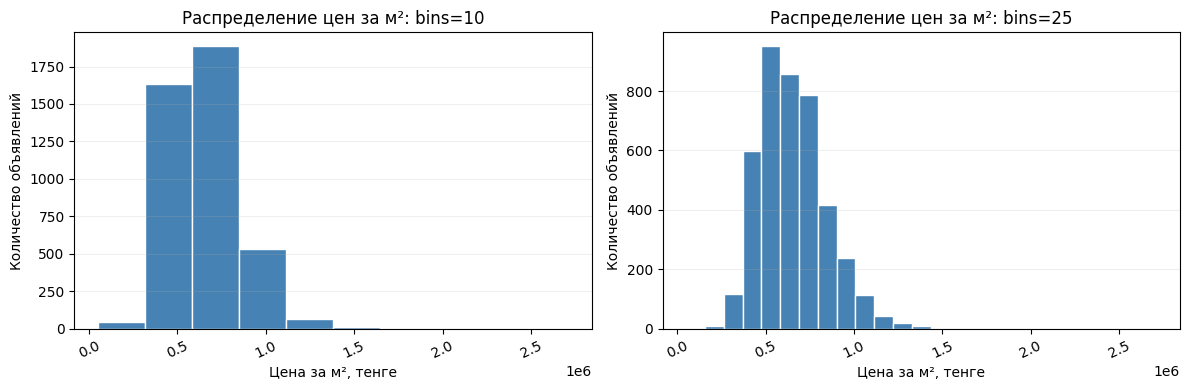

In [34]:
import matplotlib.pyplot as plt
from pathlib import Path

Path("output").mkdir(exist_ok=True)

prices_m2 = analysis_df["price_per_m2"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, bins in zip(axes, [10, 25]):
    ax.hist(prices_m2, bins=bins, color="steelblue",
            edgecolor="white")

    ax.set_title(f"Распределение цен за м²: bins={bins}")
    ax.set_xlabel("Цена за м², тенге")
    ax.set_ylabel("Количество объявлений")
    ax.grid(axis="y", alpha=0.2)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()

fig.savefig("output/chart.png", dpi=150)

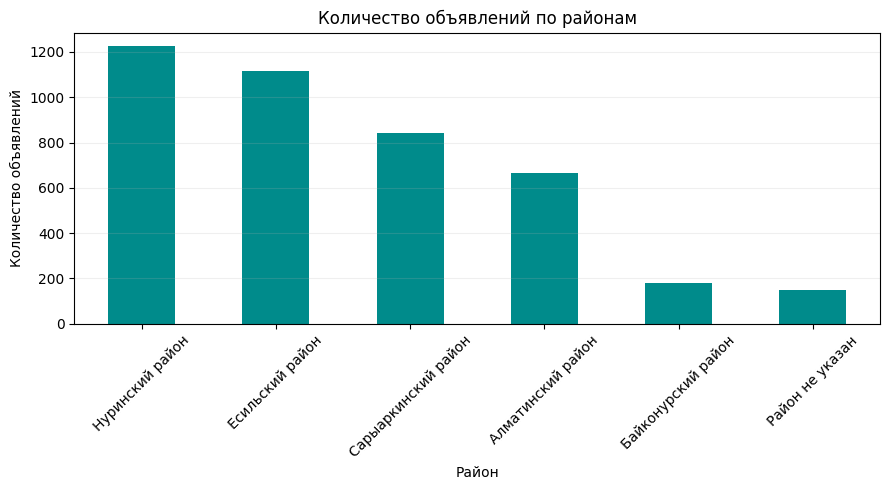

In [35]:
district_counts = (
    analysis_df["district"]
    .replace("Астана, Казахстан", "Район не указан")
    .str.replace(", Астана, Казахстан", "", regex=False)
    .value_counts(dropna=False)
)

fig, ax = plt.subplots(figsize=(9, 5))

district_counts.plot.bar(ax=ax, color="darkcyan", rot=45)

ax.set_title("Количество объявлений по районам")
ax.set_xlabel("Район")
ax.set_ylabel("Количество объявлений")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

,district_short,apartments,median_price_m2
2,Байконурский район,179,476666.67
0,Алматинский район,664,528929.60
5,Сарыаркинский район,844,537558.78
4,Нуринский район,1224,691987.18
3,Есильский район,1115,726040.66


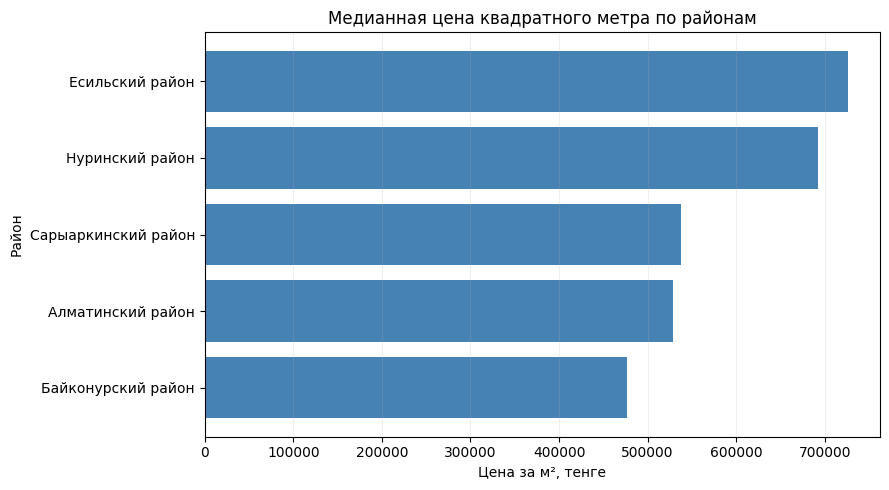

In [36]:
chart_df = district_report.loc[
    district_report["district"] != "Астана, Казахстан"
].copy()

chart_df["district_short"] = (
    chart_df["district"]
    .str.replace(", Астана, Казахстан", "", regex=False)
)

chart_df = chart_df.sort_values("median_price_m2")

display(
    chart_df[
        ["district_short", "apartments", "median_price_m2"]
    ].round(2)
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    chart_df["district_short"],
    chart_df["median_price_m2"],
    color="steelblue"
)

ax.set_title("Медианная цена квадратного метра по районам")
ax.set_xlabel("Цена за м², тенге")
ax.set_ylabel("Район")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

### Выводы по визуализации

**График 1.** Гистограммы построены по 4 173 известным значениям цены квадратного метра после очистки. Пропусков в показателе нет. Гистограмма выбрана для изучения распределения числовой величины. При увеличении bins с 10 до 25 распределение становится более детальным, хотя исходные данные не меняются. Большинство значений сосредоточено в средней части диапазона, присутствует правый хвост дорогих предложений.

**График 2.** Столбчатая диаграмма показывает количество объявлений по районам во всей очищенной выборке. Она подходит для сравнения категорий. Больше всего объявлений в Нуринском районе — 1 224. Изменение rot с 25 до 45 градусов повлияло на наклон подписей, но не на данные.

**График 3.** Горизонтальная диаграмма показывает медианные цены квадратного метра по пяти районам. 147 объявлений без уточнённого района исключены только из этого сравнения. Рядом представлена таблица с количеством объявлений в каждой группе. Наибольшая медианная цена наблюдается в Есильском районе — около 726 тыс. тенге за м². Изменение цвета столбцов не влияет на значения.

## 9. Сохранение результатов и воспроизводимость

In [37]:
report_path = "output/group_report.csv"

district_report.to_csv(
    report_path,
    index=False,
    encoding="utf-8-sig"
)

print("Отчёт сохранён:", report_path)

Отчёт сохранён: output/group_report.csv


In [38]:
report_back = pd.read_csv(report_path)

print("Количество строк:", len(report_back))
print("Столбцы:", report_back.columns.tolist())

assert len(report_back) == len(district_report)

assert report_back.columns.tolist() == district_report.columns.tolist()

assert np.isclose(
    report_back["total_asking_price"].sum(),
    district_report["total_asking_price"].sum()
)

print("Проверка сохранённого отчёта пройдена!")

display(report_back.round(2))

Количество строк: 6
Столбцы: ['district', 'apartments', 'known_prices', 'mean_price_m2', 'median_price_m2', 'total_asking_price']
Проверка сохранённого отчёта пройдена!


,district,apartments,known_prices,mean_price_m2,median_price_m2,total_asking_price
0,"Есильский район, Астана, Казахстан",1115,1115,750170.50,726040.66,65816891442
1,"Нуринский район, Астана, Казахстан",1224,1224,700219.10,691987.18,57251888098
2,"Астана, Казахстан",147,147,657567.06,620000.00,7278221877
3,"Сарыаркинский район, Астана, Казахстан",844,844,563019.15,537558.78,31885926700
4,"Алматинский район, Астана, Казахстан",664,664,573379.42,528929.60,27929902411
5,"Байконурский район, Астана, Казахстан",179,179,498536.88,476666.67,6879614074


In [39]:
import matplotlib

print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

pandas: 2.2.3
NumPy: 2.4.6
Matplotlib: 3.10.0


## 10. Итоги исследования и подготовка защиты

### Проверка исследовательских вопросов

In [40]:
rooms_report = analysis_df.groupby(
    "rooms", as_index=False
).agg(
    apartments=("url", "size"),
    median_price_m2=("price_per_m2", "median")
)

display(
    rooms_report.sort_values("rooms").round(2)
)

,rooms,apartments,median_price_m2
0,1.0,871,616216.22
1,2.0,1666,638013.14
2,3.0,1219,614678.90
3,4.0,363,700000.00
4,5.0,45,821256.04
5,6.0,4,880952.38
6,7.0,2,703607.61
7,8.0,1,813953.49
8,9.0,1,363856.88
9,10.0,1,566600.40


In [41]:
building_report = analysis_df.groupby(
    "building_type", as_index=False
).agg(
    apartments=("url", "size"),
    median_price_m2=("price_per_m2", "median")
)

display(
    building_report.sort_values(
        "median_price_m2",
        ascending=False
    ).round(2)
)

,building_type,apartments,median_price_m2
2,монолитный,2578,674287.94
0,иной,40,601724.00
1,кирпичный,1453,570652.17
3,панельный,102,484434.87


### Основные результаты исследования

В работе проанализировано 4 173 объявления о продаже квартир в Астане после удаления дубликатов и исключения одного подозрительного значения.

1. Самая высокая медианная цена предложения за квадратный метр среди определённых районов выявлена в Есильском районе — 726 041 тенге.

2. Среди квартир с одной–четырьмя комнатами самая высокая медианная цена за м² наблюдается у четырёхкомнатных — 700 000 тенге. Для квартир с большим количеством комнат выборки значительно меньше.

3. По типам домов самая высокая медианная цена за м² наблюдается у монолитных домов — 674 288 тенге, самая низкая у панельных — 484 435 тенге.

### Ограничения исследования

1. Используются цены из объявлений марта 2026 года, а не фактические цены заключённых сделок. Результаты не характеризуют актуальные цены ноября 2026 года.

2. Датасет предварительно обработан автором. Некоторые пропуски могли быть заменены условными значениями, а выборка объявлений не обязательно представляет весь рынок недвижимости Астаны.

3. Из основного анализа исключено одно объявление с аномальной ценой. Причина аномалии не установлена.

### Следующий исследовательский вопрос

Сохраняются ли различия в цене квадратного метра между монолитными, кирпичными и панельными домами, если сравнивать квартиры одинаковой площади, комнатности и района?

### Журнал использования ИИ

| Моя задача | Что подсказал ИИ | Как я проверил | Что я понял |
|---|---|---|---|
| Найти дубликаты | Использовать duplicated() и drop_duplicates() | Запустил код, сравнил количество строк до и после | Полные дубликаты могут искажать статистику |
| Проверить подозрительную цену | Рассчитать цену за м² и сравнить среднее с медианой | Нашёл аномальное объявление и сравнил результаты до и после исключения | Один выброс может сильно изменить среднее |
| Построить графики | Использовать hist(), plot.bar() и barh() | Запустил графики, изменил bins, rot и цвет | Разные графики подходят для разных аналитических вопросов |

In [42]:
%%writefile README.md
# Анализ цен предложения квартир в Астане

## О проекте
Учебный проект Week 03 по анализу данных на Python.

Исследуются цены предложения квартир в Астане на основе объявлений Krisha.kz за март 2026 года.

## Источник данных
Название: Astana Real Estate Dataset
Автор: turarr
Платформа: Kaggle
Ссылка: https://www.kaggle.com/datasets/turarr/astana-real-estate-dataset
Лицензия: CC0 Public Domain

## Используемые инструменты
- Google Colab
- Python
- pandas
- NumPy
- Matplotlib

## Как запустить проект
1. Открыть Week03_Astana_Apartments.ipynb в Google Colab.
2. Убедиться в наличии интернет-соединения.
3. Выбрать «Среда выполнения» → «Выполнить все».
4. Исходный CSV автоматически загружается из открытого репозитория автора на GitHub, если отсутствует в папке data.
5. После выполнения результаты сохраняются в папку output.

## Структура
- Week03_Astana_Apartments.ipynb — основной Notebook.
- data/astana_real_estate_dataset.csv — исходные данные.
- output/group_report.csv — отчёт по районам.
- output/chart.png — изображение гистограмм.

## Ограничения
Анализируются цены из объявлений, а не фактические цены сделок. Данные исторические, некоторые характеристики предварительно обработаны автором. Результаты не следует считать оценкой всего рынка недвижимости Астаны.

## Использование ИИ
ChatGPT использовался для объяснения команд Python, поиска ошибок, выбора аналитических операций и построения графиков. Проверка расчётов и запуск кода проводились в Google Colab.

Writing README.md


In [43]:
from pathlib import Path

print("README существует:", Path("README.md").exists())
print("CSV существует:", Path("data/astana_real_estate_dataset.csv").exists())
print("Отчёт существует:", Path("output/group_report.csv").exists())
print("График существует:", Path("output/chart.png").exists())

README существует: True
CSV существует: True
Отчёт существует: True
График существует: True
